Queremos encontrar $\pi \in \text{Adm}(Q,q):=\bigl\{ \pi \in \mathbb{H}_{\ge}(\mathcal{H}) \ : \ \operatorname{Tr}[Q_i \pi] = q_i, \ 0 \le i \le M \bigr\}$ que minimiza a seguinte expressão:

$$ \mathcal{F}_\epsilon(\pi) = Tr[H\pi]+ \epsilon Tr[\pi(log \pi -1)]$$

Podemos encontrar a forma de $\pi$ como solução para  $\mathcal{F}_\epsilon$:

$$\pi^* = \text{exp}(\frac{1}{\epsilon}(\sum_{i=0}^M u_iQ_i - H))$$

Dessa forma, o "dual" do nosso problema regularizado assume a seguinte forma:

$$
\min_{u \in \mathbb{R}^{M+1}} \left\{ \epsilon \operatorname{Tr}\left[ \exp\left( \frac{\sum_{i=0}^M u_i Q_i - H}{\epsilon} \right) \right] - \sum_{i=0}^M u_i q_i \right\}
$$

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.optimize import least_squares


# Importa as bibliotecas desenvolvida para o projeto
import quantum_tomography as qt
import entropyreg as er

In [2]:
# Teste básico
Q = [np.eye(2), qt.pauli_string_to_matrix("X"), qt.pauli_string_to_matrix("Y")]
q = [1, 0.7, 0.4]
H = 0
epsilon = 1

pistar = er.reconstruct_pi(H, Q, q, epsilon, lr=0.01, max_iters=5000, tol=1e-6)[0]
print(np.trace(pistar), np.trace(pistar @ Q[1]), np.trace(pistar @ Q[2]))
print("Matriz reconstruída pi*:")
print(pistar)

(1.0000053605606762+2.255192533269142e-17j) (0.6999953457299546+5.551115123125783e-17j) (0.3999973404171167-5.551115123125783e-17j)
Matriz reconstruída pi*:
[[0.50000268-3.01695856e-17j 0.34999767-1.99998670e-01j]
 [0.34999767+1.99998670e-01j 0.50000268+5.27215109e-17j]]


In [3]:
# Teste variando epsilon e learning rate
epsilon_values = [0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
lr_values = [0.01,0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 0.75, 1.0]

pieps = []
piepsit = []
pilr = []
pilrit = []

for epsilon in epsilon_values:
    result = er.reconstruct_pi(H, Q, q, epsilon, lr=0.01, max_iters=100000, tol=1e-6)
    pieps.append(result[0])
    piepsit.append(result[2])

for lr in lr_values:
    result = er.reconstruct_pi(H, Q, q, epsilon=1.0, lr=lr, max_iters=100000, tol=1e-6)
    pilr.append(result[0])
    pilrit.append(result[2])

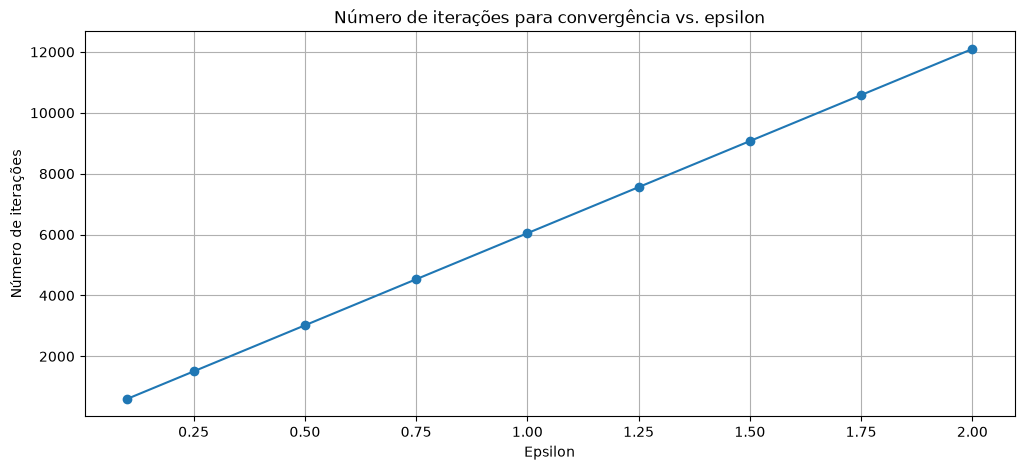

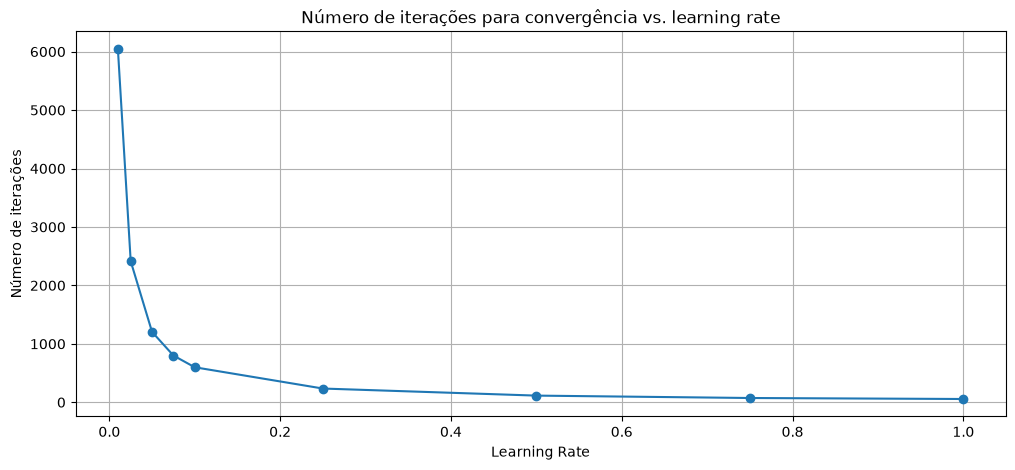

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(epsilon_values, piepsit, marker='o')
plt.title("Número de iterações para convergência vs. epsilon")
plt.xlabel("Epsilon")
plt.ylabel("Número de iterações")
plt.grid()

plt.figure(figsize=(12, 5))
plt.plot(lr_values, pilrit, marker='o')
plt.title("Número de iterações para convergência vs. learning rate")
plt.xlabel("Learning Rate")
plt.ylabel("Número de iterações")
plt.grid()

[[0, np.float64(1.4142135623730951)], [1, np.float64(1.1013906298063676)], [2, np.float64(0.9065341242931347)], [3, np.float64(0.7723011516954497)], [4, np.float64(0.6737436662639292)], [5, np.float64(0.5980937669978575)], [6, np.float64(0.5380860561562516)], [7, np.float64(0.4892616550436703)], [8, np.float64(0.44872371745617806)], [9, np.float64(0.4145043519810564)], [10, np.float64(0.3852177521269115)], [11, np.float64(0.3598586239797297)], [12, np.float64(0.3376792987596289)], [13, np.float64(0.31811176850865686)], [14, np.float64(0.3007165260718671)], [15, np.float64(0.28514800847687355)], [16, np.float64(0.27113066160936605)], [17, np.float64(0.2584419925288458)], [18, np.float64(0.2469003335066851)], [19, np.float64(0.23635585324770395)], [20, np.float64(0.2266838499996066)], [21, np.float64(0.21777967652126806)], [22, np.float64(0.20955485065272836)], [23, np.float64(0.2019340397267395)], [24, np.float64(0.19485269753667916)], [25, np.float64(0.18825519449900405)], [26, np.floa

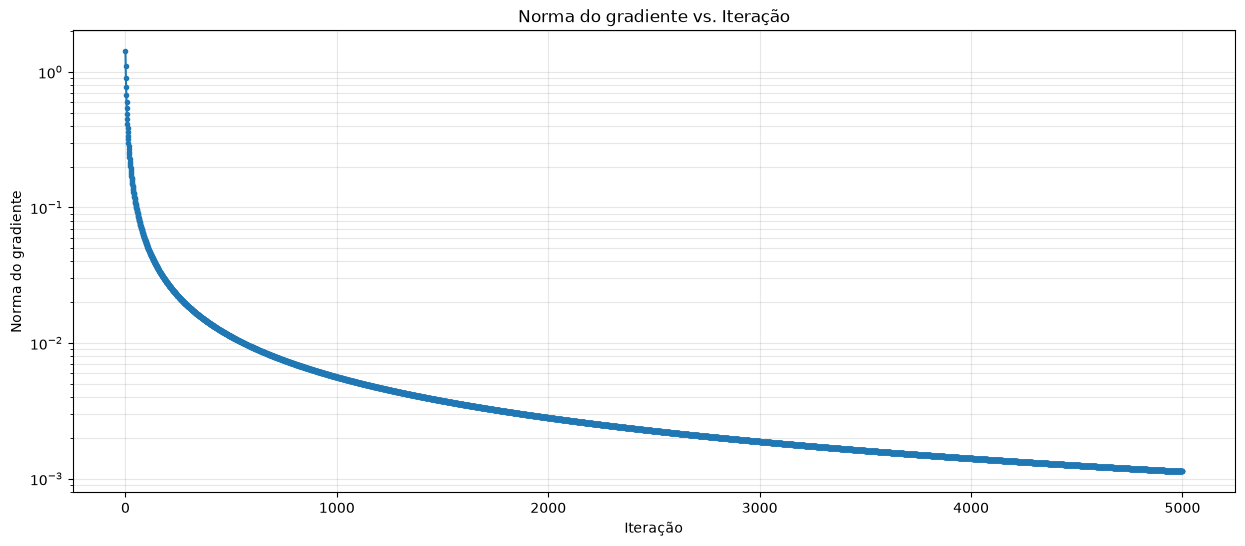

In [10]:
"""
Definimos um estado conhecido e utilizamos-no 
para determinar as medidas q. Em seguida, usamos
o gradient descento com a regularização entrópica
para reconstruir o estado. Faremos isso para 
conseguirmoss verificar a convergência do método 
a partir de um gráfico que mostra o módulo do gradiente
do problema em função do número de iterações.
"""

unk_state = qt.QuantState([2.0 / np.sqrt(5.0), 1.0 / np.sqrt(5.0)])
obs = [np.eye(2), qt.pauli_string_to_matrix("X"), qt.pauli_string_to_matrix("Y"), qt.pauli_string_to_matrix("Z")]
qs = qt.measure_observables(unk_state, obs)

conv_data = er.reconstruct_pi(H, obs, qs, epsilon, lr=0.25, max_iters=5000, tol=1e-6)[4]
print(conv_data)
data = np.array(conv_data)        
its, gnorms = data[:, 0], data[:, 1]

plt.figure(figsize=(15, 6))
plt.semilogy(its, gnorms, marker='o', markersize=3)
plt.title("Norma do gradiente vs. Iteração")
plt.xlabel("Iteração")
plt.ylabel("Norma do gradiente")
plt.grid(True, which="both", alpha=0.3)
plt.show()



## Testes para o Método Estocástico


In [6]:
# Teste básico
Q = [np.eye(2), qt.pauli_string_to_matrix("X"), qt.pauli_string_to_matrix("Y")]
q = [1, 0.7, 0.4]
H = 0
epsilon = 1

pistar, u_opt, n_it, us = er.reconstruct_spi(H, Q, q, epsilon, max_iters=5000, lr=0.01, tol=1e-6, k=2)
print("iterações:", n_it)
print(np.trace(pistar), np.trace(pistar @ Q[1]), np.trace(pistar @ Q[2]))
print("Matriz reconstruída pi*:")
print(pistar)

iterações: 5000
(1.0001445921999246+1.427239873557639e-17j) (0.6998885990167321+0j) (0.3999353581397531+0j)
Matriz reconstruída pi*:
[[0.5000723-1.14868991e-17j 0.3499443-1.99967679e-01j]
 [0.3499443+1.99967679e-01j 0.5000723+2.57592978e-17j]]


In [7]:
# Teste variando epsilon e learning rate
eps_values = [0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
lr_val = [0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 0.75, 1.0]

pieps, piepsit = [], []
pilr, pilrit = [], []

for epsilon in eps_values:
    result = er.reconstruct_spi(H, Q, q, epsilon, lr=0.01, max_iters=100000, tol=1e-6, k=2)
    pieps.append(result[0])
    piepsit.append(result[2])

for lr in lr_val:
    result = er.reconstruct_spi(H, Q, q, epsilon=1.0, lr=lr, max_iters=100000, tol=1e-6, k=2)
    pilr.append(result[0])
    pilrit.append(result[2])

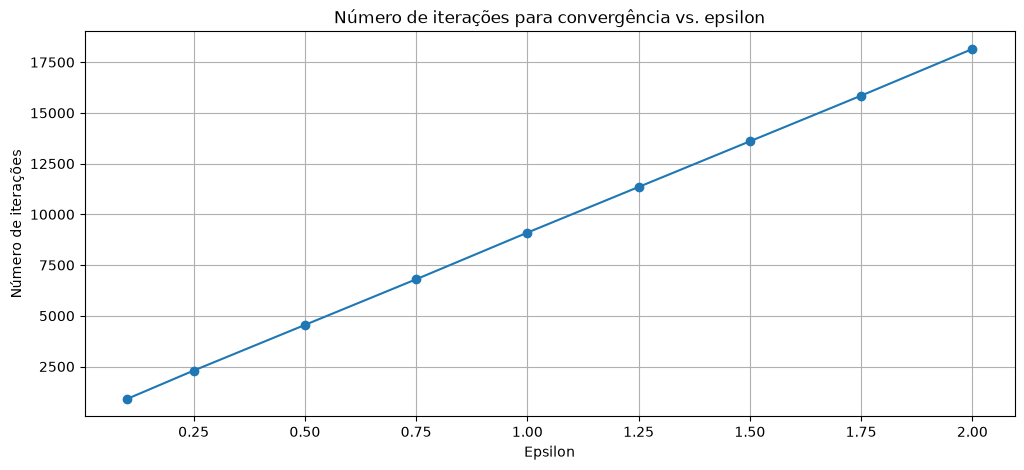

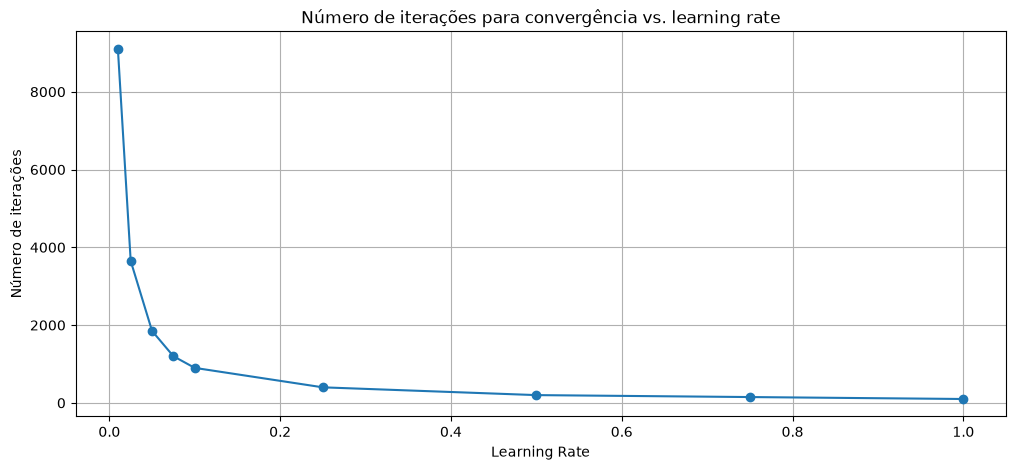

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(eps_values, piepsit, marker='o')
plt.title("Número de iterações para convergência vs. epsilon")
plt.xlabel("Epsilon")
plt.ylabel("Número de iterações")
plt.grid()

plt.figure(figsize=(12, 5))
plt.plot(lr_val, pilrit, marker='o')
plt.title("Número de iterações para convergência vs. learning rate")
plt.xlabel("Learning Rate")
plt.ylabel("Número de iterações")
plt.grid()